In [4]:
import getpass
import pandas as pd
from sqlalchemy import create_engine
from sklearn.model_selection import train_test_split

engine = create_engine(
    f"postgresql+psycopg2://{getpass.getuser()}@localhost:5432/bank"
)
df = pd.read_sql("SELECT * FROM customers", engine)

# Metin kolonları 0/1 kolonlarına çevir (one-hot encoding)
df_model = pd.get_dummies(df, columns=["geography", "gender"], drop_first=True)

features = [c for c in df_model.columns if c not in
            ("row_number", "customer_id", "surname", "exited")]
X = df_model[features]
y = df_model["exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Özellikler:", features)
print("Eğitim:", X_train.shape)
print("Test:", X_test.shape)


Özellikler: ['credit_score', 'age', 'tenure', 'balance', 'num_of_products', 'has_cr_card', 'is_active_member', 'estimated_salary', 'geography_Germany', 'geography_Spain', 'gender_Male']
Eğitim: (8000, 11)
Test: (2000, 11)


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (roc_auc_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

baseline_pred = np.zeros(len(y_test))
print("Baseline doğruluk:", round((baseline_pred == y_test).mean(), 4))
print("Baseline'ın bulduğu ayrılan müşteri:", int(baseline_pred.sum()))


Baseline doğruluk: 0.7965
Baseline'ın bulduğu ayrılan müşteri: 0


In [6]:
logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
])

cv = cross_val_score(logreg, X_train, y_train, cv=5, scoring="roc_auc")
print("CV ROC-AUC:", round(cv.mean(), 4), "+/-", round(cv.std(), 4))

logreg.fit(X_train, y_train)
proba = logreg.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print("ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
print("Precision:", round(precision_score(y_test, pred), 4))
print("Recall:", round(recall_score(y_test, pred), 4))
print("F1:", round(f1_score(y_test, pred), 4))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))


CV ROC-AUC: 0.7653 +/- 0.0138
ROC-AUC: 0.7816
Precision: 0.3989
Recall: 0.7076
F1: 0.5102
Confusion matrix:
 [[1159  434]
 [ 119  288]]


In [7]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric="auc",
    random_state=42
)
xgb.fit(X_train, y_train)

proba_xgb = xgb.predict_proba(X_test)[:, 1]
pred_xgb = xgb.predict(X_test)

print("ROC-AUC:", round(roc_auc_score(y_test, proba_xgb), 4))
print("Precision:", round(precision_score(y_test, pred_xgb), 4))
print("Recall:", round(recall_score(y_test, pred_xgb), 4))
print("F1:", round(f1_score(y_test, pred_xgb), 4))
print("Confusion matrix:\n", confusion_matrix(y_test, pred_xgb))


ROC-AUC: 0.8651
Precision: 0.513
Recall: 0.7273
F1: 0.6016
Confusion matrix:
 [[1312  281]
 [ 111  296]]


In [8]:
comparison = pd.DataFrame({
    "Model": ["Lojistik Regresyon", "XGBoost"],
    "ROC-AUC": [roc_auc_score(y_test, proba), roc_auc_score(y_test, proba_xgb)],
    "Precision": [precision_score(y_test, pred), precision_score(y_test, pred_xgb)],
    "Recall": [recall_score(y_test, pred), recall_score(y_test, pred_xgb)],
    "F1": [f1_score(y_test, pred), f1_score(y_test, pred_xgb)],
}).round(4)
comparison


,Model,ROC-AUC,Precision,Recall,F1
0,Lojistik Regresyon,0.7816,0.3989,0.7076,0.5102
1,XGBoost,0.8651,0.5130,0.7273,0.6016


/Users/Aleyna/bank_analyse/bank-customer-churn-analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


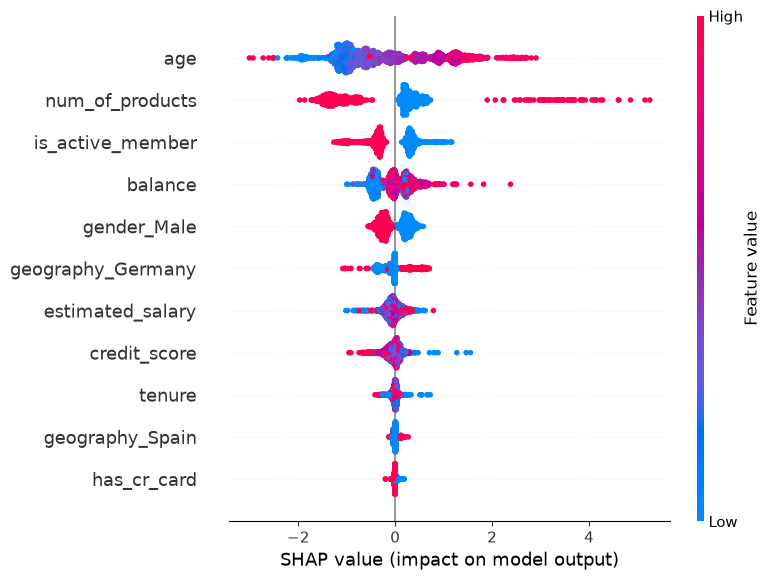

In [9]:
import shap

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test)

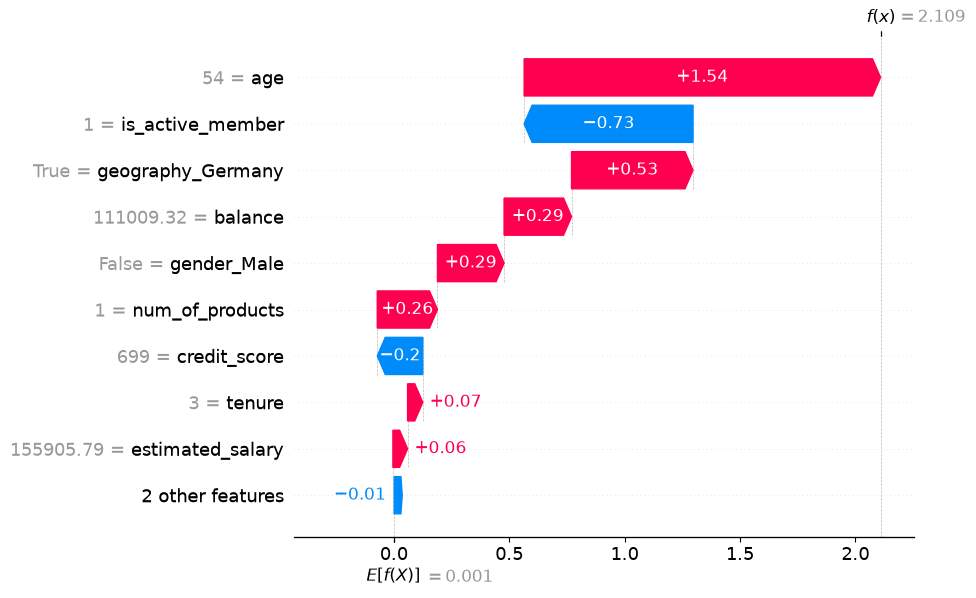

In [10]:
# Test setinden ayrılan bir müşteri seç
idx = y_test[y_test == 1].index[0]
i = X_test.index.get_loc(idx)

shap.waterfall_plot(shap.Explanation(
    values=shap_values[i],
    base_values=explainer.expected_value,
    data=X_test.iloc[i],
    feature_names=X_test.columns
))


In [11]:
import joblib, os
os.makedirs("../models", exist_ok=True)
joblib.dump({"model": xgb, "columns": list(X_train.columns)}, "../models/xgb_churn.joblib")
print("kaydedildi")


kaydedildi


In [ ]:
import joblib, os
os.makedirs("../models", exist_ok=True)
joblib.dump({"model": xgb, "columns": list(X_train.columns)}, "../models/xgb_churn.joblib")
print("kaydedildi")


kaydedildi


In [ ]:
import joblib, os
os.makedirs("../models", exist_ok=True)
joblib.dump({"model": xgb, "columns": list(X_train.columns)}, "../models/xgb_churn.joblib")
print("kaydedildi")


kaydedildi


In [ ]:
import joblib, os
os.makedirs("../models", exist_ok=True)
joblib.dump({"model": xgb, "columns": list(X_train.columns)}, "../models/xgb_churn.joblib")
print("kaydedildi")


kaydedildi
